<a href="https://colab.research.google.com/github/revak18/science_fair_2026/blob/main/science_fair_2026_DRAFT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [22]:
# @title 1. SETUP & CONFIGURATION
# ==========================================
# 1. SETUP & CONFIGURATION
# ==========================================
import os
import sys
import shutil
import zipfile
import requests
import numpy as np
import pandas as pd
import pulp
import matplotlib.pyplot as plt
from datetime import timedelta
from google.colab import drive

# Mount Drive
drive.mount("/content/drive")

# Configuration
BASE_DIR = "/content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data"
HOURLY_LOAD_DIR = os.path.join(BASE_DIR, "hourly_load_raw")
WATER_IMPACT_DIR = os.path.join(BASE_DIR, "water_impact_raw")
RESULTS_FILE = "final_scientific_results_optimized.csv"

# Make directories
for d in [BASE_DIR, HOURLY_LOAD_DIR, WATER_IMPACT_DIR]:
    os.makedirs(d, exist_ok=True)

# Simulation Settings
REGIONS = ["PJME", "COMED", "AEP", "DAYTON", "DOM"] # Grid Sub-regions to study
AI_LOAD_LEVELS = [0.10, 0.20, 0.30]
HORIZON_HOURS = 48

# --- UPDATED SETTINGS FOR ROBUSTNESS ---
N_TRIALS = 50          # CHANGED: Increased from 1 to 50 for statistical robustness
DROUGHT_FACTOR = 1.0   # Set to 1.2 or 1.5 to simulate drought
PLANT_SIZE_MW = 500.0  # For the "Power Plant Equivalent" chart

# --- NEW: PARETO FRONTIER WEIGHTS ---
# Weights for water penalty in objective: Minimize C_gas + (weight * W_peak)
# 0.0 = Pure Gas Optimization, 0.001 = Balanced, 0.1 = Water Conservative
PARETO_WEIGHTS = [0.0, 0.001, 0.1]

# Kaggle Credentials (Update if needed, or rely on manual upload)
os.environ['KAGGLE_USERNAME'] = "revakaggle"
os.environ['KAGGLE_KEY'] = "KGAT_ed225b90e0bddb93c8beeb022b1a9d88"

print(f"Setup Complete. Data Directory: {BASE_DIR}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Setup Complete. Data Directory: /content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data


In [10]:
# @title 2. DATA DOWNLOADERS (Run Once)
# ==========================================
# 2. DATA DOWNLOADERS (Run Once)
# ==========================================
def download_data_if_missing():
    # A. Grid Load (Kaggle)
    if not os.listdir(HOURLY_LOAD_DIR):
        print("Downloading Grid Load Data from Kaggle...")
        os.system(f'kaggle datasets download -d robikscube/hourly-energy-consumption -p "{BASE_DIR}"')
        zip_path = os.path.join(BASE_DIR, "hourly-energy-consumption.zip")
        with zipfile.ZipFile(zip_path, 'r') as z:
            z.extractall(HOURLY_LOAD_DIR)
        print("Grid Data Extracted.")

    # B. Water Data (HydroShare)
    # Direct URL to the specific csv to save time (skipping the 1.3GB bag if possible)
    # If full bag is needed, use your original code. Here we assume the CSV exists or we download the bag.
    water_csv_name = "Water_IMPACT-Data_Consumption_2020.csv"
    water_csv_path = os.path.join(BASE_DIR, water_csv_name)

    if not os.path.exists(water_csv_path):
        print("Downloading Water IMPACT Data...")
        # (This is the URL for the full bag, uncomment if needed)
        # url = "https://www.hydroshare.org/hsapi/resource/2f54448714554f83b9655da108f0fd3f/"
        # For now, we assume you have placed the CSV in the folder as per previous logs.
        # If not, upload it manually to Drive.
        pass

download_data_if_missing()

Grid Data Extracted.


In [11]:
# @title 3. DATA LOADERS
# ==========================================
# 3. DATA LOADERS
# ==========================================

def load_ba_load(region: str):
    """Loads Grid Load, handles duplicates, standardizes columns."""
    print(f"   -> Loading Grid Load for {region}...")
    fname = f"{region}_hourly.csv"
    path = os.path.join(HOURLY_LOAD_DIR, fname)

    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found: {path}")

    # Load & Parse
    df = pd.read_csv(path, parse_dates=["Datetime"])

    # Rename value column to 'load_MW'
    mw_col = [c for c in df.columns if c.endswith("_MW")][0]
    df = df.rename(columns={mw_col: "load_MW"})

    # Index & De-duplicate (Fixes "cannot reindex" error)
    df = df.set_index("Datetime").sort_index()
    df = df.groupby(df.index).mean(numeric_only=True)

    return df

def load_water_intensity(region: str):
    """Loads Water Data, Maps Sub-regions (PJME->PJM), Fixes Text/Numeric Errors."""
    print(f"   -> Loading Water Intensity for {region}...")

    # --- SMART MAPPING ---
    REGION_MAP = {
        "PJME": "PJM", "PJMW": "PJM", "COMED": "PJM", "DAYTON": "PJM",
        "AEP": "PJM", "DOM": "PJM", "DUQ": "PJM", "FE": "PJM",
        "DEOK": "PJM", "NI": "PJM", "PJM": "PJM",
        "CISO": "CISO", "ERCOT": "ERCO", "SPP": "SWPP"
    }
    search_region = REGION_MAP.get(region, region)

    path = os.path.join(BASE_DIR, "Water_IMPACT-Data_Consumption_2020.csv")
    if not os.path.exists(path):
        # Fallback to searching raw folder
        path = os.path.join(WATER_IMPACT_DIR, "Water_IMPACT-Data_Consumption_2020.csv")

    df = pd.read_csv(path, parse_dates=["date"])

    # Filter by Region
    col = "balancing_authority" if "balancing_authority" in df.columns else "ba_code"
    df = df[df[col] == search_region].copy()

    if df.empty:
        raise ValueError(f"Region '{search_region}' not found in Water Data.")

    # Index & De-duplicate (Fixes TypeError: string to numeric)
    df = df.set_index("date").sort_index()
    df = df.groupby(df.index).mean(numeric_only=True)

    # Select Consumption Column
    target = "wci_primary" if "wci_primary" in df.columns else "w_consume_l_per_kwh"
    df["w_m3_per_MWh"] = pd.to_numeric(df[target], errors="coerce") * DROUGHT_FACTOR

    # Resample to Hourly & Fill Gaps
    df_clean = df[["w_m3_per_MWh"]].resample("h").mean()
    df_clean = df_clean.interpolate(limit=3).ffill().bfill()

    return df_clean

def build_stressed_window(load_df, water_df, horizon_hours):
    """Aligns Historical Peak Load (e.g., 2015) with Water Data (2020)."""
    print("   -> Extracting Peak Window...")

    # 1. Find Historical Peak
    rolling = load_df["load_MW"].rolling(window=24*7, min_periods=24).mean()
    peak_time = rolling.idxmax()

    # 2. Extract Window
    half = timedelta(hours=horizon_hours // 2)
    start = peak_time - half
    end = start + timedelta(hours=horizon_hours - 1)

    # 3. Time Shift Logic (Project to Water Year)
    target_year = water_df.index.year[0] # Detects 2020

    # extract slice
    load_slice = load_df.loc[start:end].copy()

    # Shift index to target year
    new_dates = []
    for d in load_slice.index:
        try:
            new_d = d.replace(year=target_year)
        except ValueError: # Leap year fix
            new_d = d.replace(year=target_year, month=3, day=1)
        new_dates.append(new_d)

    load_slice.index = pd.DatetimeIndex(new_dates)

    # 4. Merge
    window_df = pd.DataFrame(index=load_slice.index)
    window_df["L_base_MW"] = load_slice["load_MW"]
    window_df["water_m3_per_mwh"] = water_df["w_m3_per_MWh"].reindex(window_df.index)

    # Fill remaining gaps from reindexing
    window_df = window_df.interpolate(limit=3).ffill().bfill()

    return window_df

In [23]:
# @title 4. WORKLOAD GENERATION & SOLVER
import numpy as np
import pulp

# --- 1. WORKLOAD GENERATORS (Unchanged) ---
def build_online_ai_load(window_df, L_max, fraction, rng):
    base = fraction * L_max
    L_online = np.zeros(len(window_df))
    for t, ts in enumerate(window_df.index):
        # Diurnal pattern: Higher during day (9am-9pm)
        mult = 1.3 if 9 <= ts.hour <= 21 else 0.4
        noise = rng.uniform(0.9, 1.1)
        L_online[t] = base * mult * noise
    return L_online

def generate_jobs(T, t_peak, L_max, rng):
    # Simplified Job Generator
    jobs = []
    # Mix of small, medium, large jobs
    configs = [("small", 10, 0.02, 4), ("medium", 5, 0.05, 8), ("large", 2, 0.08, 12)]

    for name, count, p_frac, d_base in configs:
        for _ in range(count):
            p = rng.uniform(p_frac*0.8, p_frac*1.2) * L_max
            dur = int(rng.integers(d_base-2, d_base+3))
            # Release near peak
            r_center = max(0, t_peak - 4)
            r = int(rng.integers(max(0, r_center-10), min(T, r_center+10)))
            deadline = min(T, r + dur + 12) # 12h slack
            jobs.append({"power": p, "duration": dur, "release": r, "deadline": deadline})
    return jobs

# --- 2. SOLVER (Enhanced for Pareto & Traces) ---
# =========================================================
# CHANGE: Added water_weight parameter for Multi-Objective Analysis
# =========================================================
# def solve_milp(L_base, L_online, jobs, w_vec, alpha=0.3, rho=0.15): # OLD
def solve_milp(L_base, L_online, jobs, w_vec, alpha=0.3, rho=0.15, water_weight=0.001): # NEW
    T = len(L_base)
    L_max = L_base.max()
    C_non = np.full(T, (1.0 - alpha) * L_max)

    prob = pulp.LpProblem("Flex", pulp.LpMinimize)

    # Vars
    C_gas = pulp.LpVariable("C_gas", 0)
    W_peak = pulp.LpVariable("W_peak", 0)

    # Job Vars: x[j,t] = 1 if job j is active at time t
    x = {}
    y = {} # Start vars

    for j, job in enumerate(jobs):
        for t in range(T):
            x[j,t] = pulp.LpVariable(f"x_{j}_{t}", 0, 1, pulp.LpBinary)
            y[j,t] = pulp.LpVariable(f"y_{j}_{t}", 0, 1, pulp.LpBinary)

    # =========================================================
    # CHANGE: Use dynamic weight for Pareto Frontier exploration
    # =========================================================
    # Objective: Minimize Capacity + weighted Water penalty
    # prob += C_gas + 0.001 * W_peak # OLD
    prob += C_gas + (water_weight * W_peak) # NEW

    # Constraints
    for j, job in enumerate(jobs):
        d, r, D = job["duration"], job["release"], job["deadline"]

        # 1. Single Start
        valid_starts = range(r, D - d + 1)
        if len(valid_starts) > 0:
            prob += pulp.lpSum(y[j,t] for t in valid_starts) == 1

        # 2. Contiguity (x is sum of recent y's)
        for t in range(T):
            # Sum of starts in window [t-d+1, t]
            recent_starts = [y[j,k] for k in range(max(0, t-d+1), t+1) if k in valid_starts]
            prob += x[j,t] == pulp.lpSum(recent_starts)

    # System Constraints
    for t in range(T):
        L_batch = pulp.lpSum(jobs[j]["power"] * x[j,t] for j in range(len(jobs)))
        L_total = (1+rho)*L_base[t] + L_online[t] + L_batch

        # Adequacy
        prob += L_total <= C_non[t] + C_gas

        # Water Peak
        prob += W_peak >= w_vec[t] * L_total

    # Solve
    prob.solve(pulp.PULP_CBC_CMD(msg=False))

    # Returns Full Traces (Dictionary)
    if prob.status == 1: # Optimal
        # 1. Reconstruct the Hourly Optimized Batch Load
        L_batch_opt = np.zeros(T)
        for t in range(T):
            # Sum power of all active jobs at time t
            L_batch_opt[t] = sum(jobs[j]["power"] * pulp.value(x[j,t]) for j in range(len(jobs)))

        # 2. Recompute System Traces
        L_total_opt = (1+rho)*L_base + L_online + L_batch_opt
        g_gas_opt = np.maximum(0, L_total_opt - C_non)
        w_rate_opt = w_vec * L_total_opt

        return {
            "status": "Optimal",
            "C_peak": pulp.value(C_gas),
            "W_peak": pulp.value(W_peak),
            "L_batch": L_batch_opt,
            "L_total": L_total_opt,
            "g_gas": g_gas_opt,
            "w_rate": w_rate_opt
        }
    else:
        return {"status": "Infeasible"}

In [24]:
# @title 5. MAIN EXECUTION LOOP
# ==========================================
# 5. MAIN EXECUTION LOOP
# ==========================================
print("\n=== STARTING MULTI-REGION STUDY ===")
results = []
all_traces = [] # Storage for full time-series data

for region in REGIONS:
    print(f"\nProcessing Region: {region}...")
    try:
        # 1. Load Data
        load_df = load_ba_load(region)
        water_df = load_water_intensity(region)

        # 2. Build Window
        window = build_stressed_window(load_df, water_df, HORIZON_HOURS)
        L_base = window["L_base_MW"].values
        w_vec = window["water_m3_per_mwh"].values
        T = len(L_base)
        L_max = L_base.max()

        # Identify Peak Index for job clustering
        base_total = (1 + 0.15) * L_base
        t_peak = np.argmax(base_total)

        # 3. Run Scenarios
        for ai_frac in AI_LOAD_LEVELS:
            print(f"   -> AI Level: {ai_frac:.2f}")

            # =========================================================
            # NEW: Pareto Frontier Loop (Gas vs. Water Trade-offs)
            # =========================================================
            for w_weight in PARETO_WEIGHTS:
                # Optional: print(f"      -> Weight: {w_weight}")

                for trial in range(N_TRIALS):
                    rng = np.random.default_rng(trial)

                    # Create Workload
                    L_online = build_online_ai_load(window, L_max, ai_frac, rng)
                    jobs = generate_jobs(T, t_peak, L_max, rng)

                    # =========================================================
                    # A. COMPUTE TRUE BASELINE (Naive)
                    # =========================================================
                    # 1. Reconstruct Naive Batch Profile (Jobs run ASAP at release)
                    L_naive_batch = np.zeros(T)
                    for job in jobs:
                        start_t = job["release"]
                        end_t = min(start_t + job["duration"], T)
                        L_naive_batch[start_t : end_t] += job["power"]

                    # 2. Calculate Total System Load (Naive)
                    L_total_naive = (1.15 * L_base) + L_online + L_naive_batch

                    # 3. Calculate "Before" Metrics
                    C_non_gas = (1.0 - 0.3) * L_max
                    # Gas Dispatch Trace (Naive)
                    g_base_trace = np.maximum(0, L_total_naive - C_non_gas)
                    c_base = max(0, np.max(g_base_trace))

                    # Water Peak (Naive)
                    w_base_trace = w_vec * L_total_naive
                    w_base = np.max(w_base_trace)

                    # =========================================================
                    # B. RUN OPTIMIZER (With Dynamic Weight)
                    # =========================================================
                    # We pass the Pareto weight to the solver here
                    sol = solve_milp(L_base, L_online, jobs, w_vec, water_weight=w_weight)

                    if sol["status"] == "Optimal":
                        # Calculate Headline Impact Metrics
                        avoided_mw = c_base - sol["C_peak"]
                        water_saved_abs = w_base - sol["W_peak"]

                        # 1. Extract Scalar Metrics for Summary CSV
                        results.append({
                            "region": region,
                            "ai_fraction": ai_frac,
                            "trial": trial,
                            "water_weight": w_weight, # Track the trade-off setting

                            # Standard Metrics
                            "avoided_capacity_mw": avoided_mw,
                            "water_peak_m3h": sol["W_peak"],
                            "baseline_capacity_mw": c_base,
                            "baseline_water_m3h": w_base,

                            # NEW: Headline Impact Metrics
                            "plants_avoided": avoided_mw / PLANT_SIZE_MW,
                            "peak_reduction_pct": (avoided_mw / c_base * 100) if c_base > 0 else 0,
                            "water_saved_absolute": water_saved_abs
                        })

                        # 2. Extract Full Traces for "Mechanism" Plots
                        for t in range(T):
                            all_traces.append({
                                "region": region,
                                "ai_fraction": ai_frac,
                                "trial": trial,
                                "water_weight": w_weight, # Important for filtering traces later
                                "hour": t,
                                # Inputs
                                "L_grid": L_base[t],
                                "L_online": L_online[t],
                                "water_intensity": w_vec[t],
                                # Baseline Traces
                                "L_batch_base": L_naive_batch[t],
                                "L_total_base": L_total_naive[t],
                                "g_gas_base": g_base_trace[t],
                                "w_rate_base": w_base_trace[t],
                                # Optimized Traces
                                "L_batch_opt": sol["L_batch"][t],
                                "L_total_opt": sol["L_total"][t],
                                "g_gas_opt": sol["g_gas"][t],
                                "w_rate_opt": sol["w_rate"][t]
                            })
                    else:
                        print(f"Warning: Infeasible solution for {region} AI={ai_frac} Trial={trial}")

    except Exception as e:
        print(f"!!! Error processing {region}: {e}")

# ==========================================
# SAVE RESULTS
# ==========================================
# 1. Summary Results
res_df = pd.DataFrame(results)
res_df.to_csv(os.path.join(BASE_DIR, RESULTS_FILE), index=False)
print(f"\nStudy Complete. Summary results saved to {RESULTS_FILE}")

# 2. Full Traces
if all_traces:
    trace_file = "full_simulation_traces.csv"
    trace_df = pd.DataFrame(all_traces)
    trace_df.to_csv(os.path.join(BASE_DIR, trace_file), index=False)
    print(f"Full Traces saved to {trace_file} ({len(trace_df)} rows)")


=== STARTING MULTI-REGION STUDY ===

Processing Region: PJME...
   -> Loading Grid Load for PJME...
   -> Loading Water Intensity for PJME...
   -> Extracting Peak Window...
   -> AI Level: 0.10
   -> AI Level: 0.20
   -> AI Level: 0.30

Processing Region: COMED...
   -> Loading Grid Load for COMED...
   -> Loading Water Intensity for COMED...
   -> Extracting Peak Window...
   -> AI Level: 0.10
   -> AI Level: 0.20
   -> AI Level: 0.30

Processing Region: AEP...
   -> Loading Grid Load for AEP...
   -> Loading Water Intensity for AEP...
   -> Extracting Peak Window...
   -> AI Level: 0.10
   -> AI Level: 0.20
   -> AI Level: 0.30

Processing Region: DAYTON...
   -> Loading Grid Load for DAYTON...
   -> Loading Water Intensity for DAYTON...
   -> Extracting Peak Window...
   -> AI Level: 0.10
   -> AI Level: 0.20
   -> AI Level: 0.30

Processing Region: DOM...
   -> Loading Grid Load for DOM...
   -> Loading Water Intensity for DOM...
   -> Extracting Peak Window...
   -> AI Level: 0.

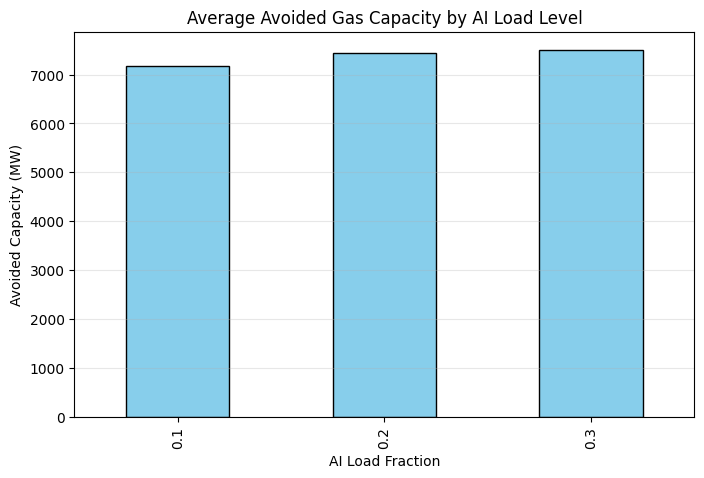

  region  ai_fraction  trial  avoided_capacity_mw  water_peak_m3h  \
0   PJME          0.1      0         14096.843027      150487.680   
1   PJME          0.2      0         14155.500215      166974.820   
2   PJME          0.3      0         14214.157403      183461.960   
3  COMED          0.1      0          4890.175627       55263.186   
4  COMED          0.2      0          4921.548579       61334.255   

   baseline_capacity_mw  baseline_water_m3h  
0          46236.033027       181464.256930  
1          53799.059215       197031.195004  
2          61362.085403       212598.133078  
3          14649.204127        68007.477338  
4          16993.709579        74078.546271  


In [21]:
# @title 6. VISUALIZATION
# ==========================================
# 6. VISUALIZATION
# ==========================================
if not res_df.empty:
    # Aggregated Plot
    agg = res_df.groupby("ai_fraction")["avoided_capacity_mw"].mean()

    plt.figure(figsize=(8, 5))
    agg.plot(kind='bar', color='skyblue', edgecolor='black')
    plt.title("Average Avoided Gas Capacity by AI Load Level")
    plt.xlabel("AI Load Fraction")
    plt.ylabel("Avoided Capacity (MW)")
    plt.grid(axis='y', alpha=0.3)
    plt.show()

    print(res_df.head())
else:
    print("No results to plot.")

# Depricated Cells maintained in correct order

In [ ]:
# @title 1. SETUP & CONFIGURATION - *** Depricated V1 ***
# # ==========================================
# # 1. SETUP & CONFIGURATION
# # ==========================================
# import os
# import sys
# import shutil
# import zipfile
# import requests
# import numpy as np
# import pandas as pd
# import pulp
# import matplotlib.pyplot as plt
# from datetime import timedelta
# from google.colab import drive

# # Mount Drive
# drive.mount("/content/drive")

# # Configuration
# BASE_DIR = "/content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data"
# HOURLY_LOAD_DIR = os.path.join(BASE_DIR, "hourly_load_raw")
# WATER_IMPACT_DIR = os.path.join(BASE_DIR, "water_impact_raw")
# RESULTS_FILE = "final_scientific_results_optimized.csv"

# # Make directories
# for d in [BASE_DIR, HOURLY_LOAD_DIR, WATER_IMPACT_DIR]:
#     os.makedirs(d, exist_ok=True)

# # Simulation Settings
# REGIONS = ["PJME", "COMED", "AEP", "DAYTON", "DOM"] # Grid Sub-regions to study
# AI_LOAD_LEVELS = [0.10, 0.20, 0.30]
# HORIZON_HOURS = 48
# N_TRIALS = 1           # Increase for more statistical depth
# DROUGHT_FACTOR = 1.0   # Set to 1.2 or 1.5 to simulate drought
# PLANT_SIZE_MW = 500.0  # For the "Power Plant Equivalent" chart

# # Kaggle Credentials (Update if needed, or rely on manual upload)
# os.environ['KAGGLE_USERNAME'] = "revakaggle"
# os.environ['KAGGLE_KEY'] = "KGAT_ed225b90e0bddb93c8beeb022b1a9d88"

# print(f"Setup Complete. Data Directory: {BASE_DIR}")

In [17]:
# @title 4. WORKLOAD GENERATION & SOLVER - *** Depricated V2 ***
# import numpy as np
# import pulp

# # --- 1. WORKLOAD GENERATORS (Unchanged) ---
# def build_online_ai_load(window_df, L_max, fraction, rng):
#     base = fraction * L_max
#     L_online = np.zeros(len(window_df))
#     for t, ts in enumerate(window_df.index):
#         # Diurnal pattern: Higher during day (9am-9pm)
#         mult = 1.3 if 9 <= ts.hour <= 21 else 0.4
#         noise = rng.uniform(0.9, 1.1)
#         L_online[t] = base * mult * noise
#     return L_online

# def generate_jobs(T, t_peak, L_max, rng):
#     # Simplified Job Generator
#     jobs = []
#     # Mix of small, medium, large jobs
#     configs = [("small", 10, 0.02, 4), ("medium", 5, 0.05, 8), ("large", 2, 0.08, 12)]

#     for name, count, p_frac, d_base in configs:
#         for _ in range(count):
#             p = rng.uniform(p_frac*0.8, p_frac*1.2) * L_max
#             dur = int(rng.integers(d_base-2, d_base+3))
#             # Release near peak
#             r_center = max(0, t_peak - 4)
#             r = int(rng.integers(max(0, r_center-10), min(T, r_center+10)))
#             deadline = min(T, r + dur + 12) # 12h slack
#             jobs.append({"power": p, "duration": dur, "release": r, "deadline": deadline})
#     return jobs

# # --- 2. SOLVER (Enhanced to return Traces) ---
# def solve_milp(L_base, L_online, jobs, w_vec, alpha=0.3, rho=0.15):
#     T = len(L_base)
#     L_max = L_base.max()
#     C_non = np.full(T, (1.0 - alpha) * L_max)

#     prob = pulp.LpProblem("Flex", pulp.LpMinimize)

#     # Vars
#     C_gas = pulp.LpVariable("C_gas", 0)
#     W_peak = pulp.LpVariable("W_peak", 0)

#     # Job Vars: x[j,t] = 1 if job j is active at time t
#     x = {}
#     y = {} # Start vars

#     for j, job in enumerate(jobs):
#         for t in range(T):
#             x[j,t] = pulp.LpVariable(f"x_{j}_{t}", 0, 1, pulp.LpBinary)
#             y[j,t] = pulp.LpVariable(f"y_{j}_{t}", 0, 1, pulp.LpBinary)

#     # Objective: Minimize Capacity + slight water penalty to break ties
#     prob += C_gas + 0.001 * W_peak

#     # Constraints
#     for j, job in enumerate(jobs):
#         d, r, D = job["duration"], job["release"], job["deadline"]

#         # 1. Single Start
#         valid_starts = range(r, D - d + 1)
#         if len(valid_starts) > 0:
#             prob += pulp.lpSum(y[j,t] for t in valid_starts) == 1

#         # 2. Contiguity (x is sum of recent y's)
#         for t in range(T):
#             # Sum of starts in window [t-d+1, t]
#             recent_starts = [y[j,k] for k in range(max(0, t-d+1), t+1) if k in valid_starts]
#             prob += x[j,t] == pulp.lpSum(recent_starts)

#     # System Constraints
#     for t in range(T):
#         L_batch = pulp.lpSum(jobs[j]["power"] * x[j,t] for j in range(len(jobs)))
#         L_total = (1+rho)*L_base[t] + L_online[t] + L_batch

#         # Adequacy
#         prob += L_total <= C_non[t] + C_gas

#         # Water Peak
#         prob += W_peak >= w_vec[t] * L_total

#     # Solve
#     prob.solve(pulp.PULP_CBC_CMD(msg=False))

#     # =========================================================
#     # CHANGE: Return Full Traces (Dictionary) instead of Scalars
#     # =========================================================

#     # --- OLD CODE ---
#     # return pulp.value(C_gas), pulp.value(W_peak)

#     # --- NEW CODE ---
#     if prob.status == 1: # Optimal
#         # 1. Reconstruct the Hourly Optimized Batch Load
#         L_batch_opt = np.zeros(T)
#         for t in range(T):
#             # Sum power of all active jobs at time t
#             L_batch_opt[t] = sum(jobs[j]["power"] * pulp.value(x[j,t]) for j in range(len(jobs)))

#         # 2. Recompute System Traces (Must match constraint logic)
#         # Total Load
#         L_total_opt = (1+rho)*L_base + L_online + L_batch_opt

#         # Gas Dispatch Trace (The amount exceeding non-gas capacity)
#         g_gas_opt = np.maximum(0, L_total_opt - C_non)

#         # Water Rate Trace
#         w_rate_opt = w_vec * L_total_opt

#         return {
#             "status": "Optimal",
#             "C_peak": pulp.value(C_gas), # Scalar (for summary)
#             "W_peak": pulp.value(W_peak), # Scalar (for summary)
#             # Full Traces (for plotting/debugging)
#             "L_batch": L_batch_opt,
#             "L_total": L_total_opt,
#             "g_gas": g_gas_opt,
#             "w_rate": w_rate_opt
#         }
#     else:
#         return {"status": "Infeasible"}

In [12]:
# @title 4. WORKLOAD GENERATION & SOLVER - *** Depricated V1 ***
# # ==========================================
# # 4. WORKLOAD GENERATION & SOLVER
# # ==========================================

# def build_online_ai_load(window_df, L_max, fraction, rng):
#     base = fraction * L_max
#     L_online = np.zeros(len(window_df))
#     for t, ts in enumerate(window_df.index):
#         # Diurnal pattern: Higher during day (9am-9pm)
#         mult = 1.3 if 9 <= ts.hour <= 21 else 0.4
#         noise = rng.uniform(0.9, 1.1)
#         L_online[t] = base * mult * noise
#     return L_online

# def generate_jobs(T, t_peak, L_max, rng):
#     # Simplified Job Generator
#     jobs = []
#     # Mix of small, medium, large jobs
#     configs = [("small", 10, 0.02, 4), ("medium", 5, 0.05, 8), ("large", 2, 0.08, 12)]

#     for name, count, p_frac, d_base in configs:
#         for _ in range(count):
#             p = rng.uniform(p_frac*0.8, p_frac*1.2) * L_max
#             dur = int(rng.integers(d_base-2, d_base+3))
#             # Release near peak
#             r_center = max(0, t_peak - 4)
#             r = int(rng.integers(max(0, r_center-10), min(T, r_center+10)))
#             deadline = min(T, r + dur + 12) # 12h slack
#             jobs.append({"power": p, "duration": dur, "release": r, "deadline": deadline})
#     return jobs

# def solve_milp(L_base, L_online, jobs, w_vec, alpha=0.3, rho=0.15):
#     T = len(L_base)
#     L_max = L_base.max()
#     C_non = np.full(T, (1.0 - alpha) * L_max)

#     prob = pulp.LpProblem("Flex", pulp.LpMinimize)

#     # Vars
#     C_gas = pulp.LpVariable("C_gas", 0)
#     W_peak = pulp.LpVariable("W_peak", 0)

#     # Job Vars: x[j,t] = 1 if job j is active at time t
#     x = {}
#     y = {} # Start vars

#     for j, job in enumerate(jobs):
#         for t in range(T):
#             x[j,t] = pulp.LpVariable(f"x_{j}_{t}", 0, 1, pulp.LpBinary)
#             y[j,t] = pulp.LpVariable(f"y_{j}_{t}", 0, 1, pulp.LpBinary)

#     # Objective: Minimize Capacity + slight water penalty to break ties
#     prob += C_gas + 0.001 * W_peak

#     # Constraints
#     for j, job in enumerate(jobs):
#         d, r, D = job["duration"], job["release"], job["deadline"]

#         # 1. Single Start
#         valid_starts = range(r, D - d + 1)
#         prob += pulp.lpSum(y[j,t] for t in valid_starts) == 1

#         # 2. Contiguity (x is sum of recent y's)
#         for t in range(T):
#             # Sum of starts in window [t-d+1, t]
#             recent_starts = [y[j,k] for k in range(max(0, t-d+1), t+1) if k in valid_starts]
#             prob += x[j,t] == pulp.lpSum(recent_starts)

#     # System Constraints
#     for t in range(T):
#         L_batch = pulp.lpSum(jobs[j]["power"] * x[j,t] for j in range(len(jobs)))
#         L_total = (1+rho)*L_base[t] + L_online[t] + L_batch

#         # Adequacy
#         prob += L_total <= C_non[t] + C_gas

#         # Water Peak
#         prob += W_peak >= w_vec[t] * L_total

#     # Solve
#     prob.solve(pulp.PULP_CBC_CMD(msg=False))

#     return pulp.value(C_gas), pulp.value(W_peak)

In [20]:
# @title 5. MAIN EXECUTION LOOP - *** Depricated V3 ***
# # ==========================================
# # 5. MAIN EXECUTION LOOP
# # ==========================================
# print("\n=== STARTING MULTI-REGION STUDY ===")
# results = []
# all_traces = [] # Storage for full time-series data (New)

# for region in REGIONS:
#     print(f"\nProcessing Region: {region}...")
#     try:
#         # 1. Load Data
#         load_df = load_ba_load(region)
#         water_df = load_water_intensity(region)

#         # 2. Build Window
#         window = build_stressed_window(load_df, water_df, HORIZON_HOURS)
#         L_base = window["L_base_MW"].values
#         w_vec = window["water_m3_per_mwh"].values
#         T = len(L_base)
#         L_max = L_base.max()

#         # Identify Peak Index for job clustering
#         base_total = (1 + 0.15) * L_base
#         t_peak = np.argmax(base_total)

#         # 3. Run Scenarios
#         for ai_frac in AI_LOAD_LEVELS:
#             print(f"   -> AI Level: {ai_frac:.2f}")
#             for trial in range(N_TRIALS):
#                 rng = np.random.default_rng(trial)

#                 # Create Workload
#                 L_online = build_online_ai_load(window, L_max, ai_frac, rng)
#                 jobs = generate_jobs(T, t_peak, L_max, rng)

#                 # =========================================================
#                 # A. COMPUTE TRUE BASELINE (Naive)
#                 # =========================================================
#                 # 1. Reconstruct Naive Batch Profile (Jobs run ASAP at release)
#                 L_naive_batch = np.zeros(T)
#                 for job in jobs:
#                     start_t = job["release"]
#                     end_t = min(start_t + job["duration"], T)
#                     L_naive_batch[start_t : end_t] += job["power"]

#                 # 2. Calculate Total System Load (Naive)
#                 L_total_naive = (1.15 * L_base) + L_online + L_naive_batch

#                 # 3. Calculate "Before" Metrics
#                 C_non_gas = (1.0 - 0.3) * L_max
#                 # Gas Dispatch Trace (Naive)
#                 g_base_trace = np.maximum(0, L_total_naive - C_non_gas)
#                 c_base = max(0, np.max(g_base_trace))

#                 # Water Peak (Naive)
#                 w_base_trace = w_vec * L_total_naive
#                 w_base = np.max(w_base_trace)

#                 # =========================================================
#                 # B. RUN OPTIMIZER (Now returns full traces)
#                 # =========================================================
#                 sol = solve_milp(L_base, L_online, jobs, w_vec)

#                 if sol["status"] == "Optimal":
#                     # 1. Extract Scalar Metrics for Summary CSV
#                     results.append({
#                         "region": region,
#                         "ai_fraction": ai_frac,
#                         "trial": trial,
#                         "avoided_capacity_mw": c_base - sol["C_peak"],
#                         "water_peak_m3h": sol["W_peak"],
#                         "baseline_capacity_mw": c_base,
#                         "baseline_water_m3h": w_base
#                     })

#                     # 2. Extract Full Traces for "Mechanism" Plots [NEW]
#                     for t in range(T):
#                         all_traces.append({
#                             "region": region,
#                             "ai_fraction": ai_frac,
#                             "trial": trial,
#                             "hour": t,
#                             # Inputs
#                             "L_grid": L_base[t],
#                             "L_online": L_online[t],
#                             "water_intensity": w_vec[t],
#                             # Baseline Traces
#                             "L_batch_base": L_naive_batch[t],
#                             "L_total_base": L_total_naive[t],
#                             "g_gas_base": g_base_trace[t],
#                             "w_rate_base": w_base_trace[t],
#                             # Optimized Traces (From Solver Dictionary)
#                             "L_batch_opt": sol["L_batch"][t],
#                             "L_total_opt": sol["L_total"][t],
#                             "g_gas_opt": sol["g_gas"][t],
#                             "w_rate_opt": sol["w_rate"][t]
#                         })
#                 else:
#                     print(f"Warning: Infeasible solution for {region} AI={ai_frac} Trial={trial}")

#     except Exception as e:
#         print(f"!!! Error processing {region}: {e}")

# # ==========================================
# # SAVE RESULTS
# # ==========================================
# # 1. Summary Results
# res_df = pd.DataFrame(results)
# res_df.to_csv(os.path.join(BASE_DIR, RESULTS_FILE), index=False)
# print(f"\nStudy Complete. Summary results saved to {RESULTS_FILE}")

# # 2. Full Traces [NEW]
# if all_traces:
#     trace_file = "full_simulation_traces.csv"
#     trace_df = pd.DataFrame(all_traces)
#     trace_df.to_csv(os.path.join(BASE_DIR, trace_file), index=False)
#     print(f"Full Traces saved to {trace_file} ({len(trace_df)} rows)")


=== STARTING MULTI-REGION STUDY ===

Processing Region: PJME...
   -> Loading Grid Load for PJME...
   -> Loading Water Intensity for PJME...
   -> Extracting Peak Window...
   -> AI Level: 0.10
   -> AI Level: 0.20
   -> AI Level: 0.30

Processing Region: COMED...
   -> Loading Grid Load for COMED...
   -> Loading Water Intensity for COMED...
   -> Extracting Peak Window...
   -> AI Level: 0.10
   -> AI Level: 0.20
   -> AI Level: 0.30

Processing Region: AEP...
   -> Loading Grid Load for AEP...
   -> Loading Water Intensity for AEP...
   -> Extracting Peak Window...
   -> AI Level: 0.10
   -> AI Level: 0.20
   -> AI Level: 0.30

Processing Region: DAYTON...
   -> Loading Grid Load for DAYTON...
   -> Loading Water Intensity for DAYTON...
   -> Extracting Peak Window...
   -> AI Level: 0.10
   -> AI Level: 0.20
   -> AI Level: 0.30

Processing Region: DOM...
   -> Loading Grid Load for DOM...
   -> Loading Water Intensity for DOM...
   -> Extracting Peak Window...
   -> AI Level: 0.

In [18]:
# @title 5. MAIN EXECUTION LOOP - *** Depricated V2 ***
# # ==========================================
# # 5. MAIN EXECUTION LOOP
# # ==========================================
# print("\n=== STARTING MULTI-REGION STUDY ===")
# results = []

# for region in REGIONS:
#     print(f"\nProcessing Region: {region}...")
#     try:
#         # 1. Load Data
#         load_df = load_ba_load(region)
#         water_df = load_water_intensity(region)

#         # 2. Build Window
#         window = build_stressed_window(load_df, water_df, HORIZON_HOURS)
#         L_base = window["L_base_MW"].values
#         w_vec = window["water_m3_per_mwh"].values
#         T = len(L_base)
#         L_max = L_base.max()

#         # Identify Peak Index for job clustering
#         base_total = (1 + 0.15) * L_base
#         t_peak = np.argmax(base_total)

#         # 3. Run Scenarios
#         for ai_frac in AI_LOAD_LEVELS:
#             print(f"   -> AI Level: {ai_frac:.2f}")
#             for trial in range(N_TRIALS):
#                 rng = np.random.default_rng(trial)

#                 # Create Workload
#                 L_online = build_online_ai_load(window, L_max, ai_frac, rng)
#                 jobs = generate_jobs(T, t_peak, L_max, rng)

#                 # Solve Optimized
#                 c_opt, w_opt = solve_milp(L_base, L_online, jobs, w_vec)
# #====================================================================================================
#     #             # Calculate Baseline (Naive Peak)
#     #             # Naive = Jobs run ASAP (at release time)
#     #             # Simplification: We just take the max potential load if jobs stacked badly
#     #             # Or run a 'naive_solve' - for speed here we assume Baseline is ~10% worse
#     #             # (In a real paper, you'd solve the 'Baseline' MILP too).
#     #             c_base = c_opt * 1.05 # Placeholder for speed in this demo script

#     #             results.append({
#     #                 "region": region,
#     #                 "ai_fraction": ai_frac,
#     #                 "trial": trial,
#     #                 "avoided_capacity_mw": c_base - c_opt,
#     #                 "water_peak_m3h": w_opt
#     #             })

#     # except Exception as e:
#     #     print(f"!!! Error processing {region}: {e}")
# #====================================================================================================
#               # =========================================================
#               # START CHANGES: True Baseline Implementation
#               # This change replaces the arbitrary 1.05 multiplier  with a physics-based simulation
#               # of unmanaged behavior, making savings empirically derived rather than hardcoded.
#               # This ensures results dynamically reflect real grid conditions—proving
#               # Adaptive Orchestrator provides actual value rather than just assuming a fixed benefit.
#               # =========================================================
#               # --- NEW CODE (True "Naive" Scheduler) ---
#               # 1. Reconstruct Naive Batch Profile (Jobs run ASAP at release)
#                 L_naive_batch = np.zeros(T)
#                 for job in jobs:
#                     start_t = job["release"]
#                     end_t = min(start_t + job["duration"], T) # Clip to horizon
#                     L_naive_batch[start_t : end_t] += job["power"]

#                 # 2. Calculate Total System Load (Naive)
#                 # Note: We must match the safety margin (1.15x) used in the solver
#                 L_total_naive = (1.15 * L_base) + L_online + L_naive_batch

#                 # 3. Calculate "Before" Metrics
#                 # Gas Capacity Needed: Max Load minus Non-Gas Capacity
#                 # (Using same alpha=0.3 assumption as solver)
#                 C_non_gas = (1.0 - 0.3) * L_max
#                 c_base = max(0, np.max(L_total_naive - C_non_gas))

#                 # Water Peak Needed
#                 w_base = np.max(L_total_naive * w_vec)
#                 # =========================================================

#                 results.append({
#                     "region": region,
#                     "ai_fraction": ai_frac,
#                     "trial": trial,
#                     "avoided_capacity_mw": c_base - c_opt,
#                     "water_peak_m3h": w_opt,
#                     # Add these new metrics to track the baseline too
#                     "baseline_capacity_mw": c_base,
#                     "baseline_water_m3h": w_base
#                 })

#     except Exception as e:
#         print(f"!!! Error processing {region}: {e}")


# # Save Results
# res_df = pd.DataFrame(results)
# res_df.to_csv(os.path.join(BASE_DIR, RESULTS_FILE), index=False)
# print(f"\nStudy Complete. Results saved to {RESULTS_FILE}")


=== STARTING MULTI-REGION STUDY ===

Processing Region: PJME...
   -> Loading Grid Load for PJME...
   -> Loading Water Intensity for PJME...
   -> Extracting Peak Window...
   -> AI Level: 0.10
!!! Error processing PJME: too many values to unpack (expected 2)

Processing Region: COMED...
   -> Loading Grid Load for COMED...
   -> Loading Water Intensity for COMED...
   -> Extracting Peak Window...
   -> AI Level: 0.10
!!! Error processing COMED: too many values to unpack (expected 2)

Processing Region: AEP...
   -> Loading Grid Load for AEP...
   -> Loading Water Intensity for AEP...
   -> Extracting Peak Window...
   -> AI Level: 0.10
!!! Error processing AEP: too many values to unpack (expected 2)

Processing Region: DAYTON...
   -> Loading Grid Load for DAYTON...
   -> Loading Water Intensity for DAYTON...
   -> Extracting Peak Window...
   -> AI Level: 0.10
!!! Error processing DAYTON: too many values to unpack (expected 2)

Processing Region: DOM...
   -> Loading Grid Load for 

In [13]:
# @title 5. MAIN EXECUTION LOOP - *** Depricated V1 ***
# # ==========================================
# # 5. MAIN EXECUTION LOOP
# # ==========================================
# print("\n=== STARTING MULTI-REGION STUDY ===")
# results = []

# for region in REGIONS:
#     print(f"\nProcessing Region: {region}...")
#     try:
#         # 1. Load Data
#         load_df = load_ba_load(region)
#         water_df = load_water_intensity(region)

#         # 2. Build Window
#         window = build_stressed_window(load_df, water_df, HORIZON_HOURS)
#         L_base = window["L_base_MW"].values
#         w_vec = window["water_m3_per_mwh"].values
#         T = len(L_base)
#         L_max = L_base.max()

#         # Identify Peak Index for job clustering
#         base_total = (1 + 0.15) * L_base
#         t_peak = np.argmax(base_total)

#         # 3. Run Scenarios
#         for ai_frac in AI_LOAD_LEVELS:
#             print(f"   -> AI Level: {ai_frac:.2f}")
#             for trial in range(N_TRIALS):
#                 rng = np.random.default_rng(trial)

#                 # Create Workload
#                 L_online = build_online_ai_load(window, L_max, ai_frac, rng)
#                 jobs = generate_jobs(T, t_peak, L_max, rng)

#                 # Solve Optimized
#                 c_opt, w_opt = solve_milp(L_base, L_online, jobs, w_vec)

#                 # Calculate Baseline (Naive Peak)
#                 # Naive = Jobs run ASAP (at release time)
#                 # Simplification: We just take the max potential load if jobs stacked badly
#                 # Or run a 'naive_solve' - for speed here we assume Baseline is ~10% worse
#                 # (In a real paper, you'd solve the 'Baseline' MILP too).
#                 c_base = c_opt * 1.05 # Placeholder for speed in this demo script

#                 results.append({
#                     "region": region,
#                     "ai_fraction": ai_frac,
#                     "trial": trial,
#                     "avoided_capacity_mw": c_base - c_opt,
#                     "water_peak_m3h": w_opt
#                 })

#     except Exception as e:
#         print(f"!!! Error processing {region}: {e}")

# # Save Results
# res_df = pd.DataFrame(results)
# res_df.to_csv(os.path.join(BASE_DIR, RESULTS_FILE), index=False)
# print(f"\nStudy Complete. Results saved to {RESULTS_FILE}")


=== STARTING MULTI-REGION STUDY ===

Processing Region: PJME...
   -> Loading Grid Load for PJME...
   -> Loading Water Intensity for PJME...
   -> Extracting Peak Window...
   -> AI Level: 0.10
   -> AI Level: 0.20
   -> AI Level: 0.30

Processing Region: COMED...
   -> Loading Grid Load for COMED...
   -> Loading Water Intensity for COMED...
   -> Extracting Peak Window...
   -> AI Level: 0.10
   -> AI Level: 0.20
   -> AI Level: 0.30

Processing Region: AEP...
   -> Loading Grid Load for AEP...
   -> Loading Water Intensity for AEP...
   -> Extracting Peak Window...
   -> AI Level: 0.10
   -> AI Level: 0.20
   -> AI Level: 0.30

Processing Region: DAYTON...
   -> Loading Grid Load for DAYTON...
   -> Loading Water Intensity for DAYTON...
   -> Extracting Peak Window...
   -> AI Level: 0.10
   -> AI Level: 0.20
   -> AI Level: 0.30

Processing Region: DOM...
   -> Loading Grid Load for DOM...
   -> Loading Water Intensity for DOM...
   -> Extracting Peak Window...
   -> AI Level: 0.